# Scaling Law Experiment — Linear Regression

This notebook implements the synthetic diagonal linear-regression model and compares
**Heavy Ball (HB)**, **Nesterov (NAG)**, and **SGD** in one shared experiment.

The parameters are set from the **noisy Nesterov** setting in the screenshot, with a
single configurable source parameter `S_VALUE`:

$$
q=2-1/\beta.
$$

For $0<s<q/2$ the optimum is attained with

$$
x^*=\frac{s}{s+q},\qquad a^*=\frac{2s}{s+q},\qquad
p^*=\frac{s q}{s+q}.
$$

For $s\ge q/2$ the displayed exponent is a supremum. The code takes a fixed
auxiliary value $y<1$ close to one and uses

$$
x^*=\frac{s-\frac12(1-1/\beta)}{s+\frac12(1+1/\beta)},\qquad
 a\uparrow \frac{1+x^*}{2},\qquad y=2a-x^*\uparrow 1.
$$

For the actual experiment budget, we enforce

$$
B K = D.
$$

Thus $B\asymp D^a$ and $K=D/B\asymp D^{1-a}$. All three algorithms use the same
$B,K,\eta$ schedule. HB and NAG use the scheduled momentum, while SGD keeps
$\rho=0$ by definition.


## 1. Setting

$$
\text{Label:}\quad y=\langle\theta^*,x\rangle+\varepsilon,\quad \varepsilon\sim\mathcal{N}(0,\sigma^2)
$$
$$
\text{Data:}\quad x\sim\mathcal{N}(0,H),\qquad H=\mathrm{diag}(\lambda_i),\qquad \lambda_i\asymp i^{-\beta}
$$
$$
\text{Task:}\quad \theta_j^{*\,2}\sim j^{-1-(s-1)\beta}
$$

Because $H$ is diagonal, we work directly in the eigenbasis: each coordinate is independent with
$x_j\sim\mathcal{N}(0,\lambda_j)$. The **population** (test) loss splits into an irreducible part
and the **excess loss**
$$
L(\theta)=\tfrac12\sigma^2+\underbrace{\tfrac12(\theta-\theta^*)^\top H(\theta-\theta^*)}_{\mathcal{E}(\theta)},
\qquad
\mathcal{E}(\theta)=\tfrac12\sum_j \lambda_j\,(\theta_j-\theta_j^*)^2 .
$$
We evaluate $\mathcal{E}$ **analytically** (it is the exact population excess loss), which is both
exact and cheaper than a Monte-Carlo test set.


In [71]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------- model / task parameters -----------------------------
BETA  = 2.0     # spectrum decay lambda_j ~ j^{-beta}; q=2-1/beta=1.5
SIGMA = 1.0     # noisy case: sigma > 0
DIM   = 4096    # ambient dimension (truncation of the infinite spectrum)

# Single source-smoothness parameter.
# For BETA=2: S_VALUE < 0.75 uses branch 1; S_VALUE >= 0.75 uses branch 2.
S_VALUE = 0.5


def build_problem(dim=DIM, beta=BETA, s=1.0):
    """Return (lam, theta_star) for the diagonal linear-regression problem."""
    j = np.arange(1, dim + 1, dtype=np.float64)
    lam = j ** (-beta)
    var_star = j ** (-(1.0 + (s - 1.0) * beta))
    theta_star = np.sqrt(var_star)
    return lam, theta_star


def excess_loss(delta, lam):
    """Exact population excess loss E = 1/2 * sum_j lam_j * delta_j^2."""
    return 0.5 * np.sum(lam * delta * delta)


q_value = 2.0 - 1.0 / BETA
lam, theta_star = build_problem(s=S_VALUE)
print(f'beta={BETA:g}, q={q_value:.3f}, q/2={0.5 * q_value:.3f}, sigma={SIGMA:g}, dim={DIM}')
print(f's={S_VALUE:.3f}')
print(f'lambda range [{lam[-1]:.2e}, {lam[0]:.2e}], initial excess loss E(0)={excess_loss(-theta_star, lam):.4f}')


beta=2, q=1.500, q/2=0.750, sigma=1, dim=4096
s=0.500
lambda range [5.96e-08, 1.00e+00], initial excess loss E(0)=0.8223


## 2. Data generation & stochastic gradient

For a minibatch of size $B$ we draw fresh samples $x_i\sim\mathcal{N}(0,H)$ and
$y_i=\langle\theta^*,x_i\rangle+\varepsilon_i$. Writing $\delta=\theta-\theta^*$, the empirical
gradient is
$$
\nabla\hat L(\theta)=\frac1B\sum_{i=1}^B\big(\langle\delta,x_i\rangle-\varepsilon_i\big)\,x_i
= H\delta+\xi,\qquad \xi\ \text{the gradient noise}.
$$
We run a **single pass** over the data, so the total number of samples consumed is
$B\cdot K = D$ on the current power-of-two grid, so this is exactly the data budget used in the scaling analysis.
Tracking $\delta$ directly (instead of $\theta$) is convenient because $\theta^*$ is constant and
all update rules are affine in $\delta$.


In [72]:
def sample_batch(B, lam, sigma=SIGMA, rng=None):
    """Draw a minibatch. Returns X (B,d) with columns scaled by sqrt(lam) and eps (B,)."""
    rng = rng or np.random.default_rng()
    d = lam.shape[0]
    X = rng.standard_normal((B, d)) * np.sqrt(lam)
    eps = rng.standard_normal(B) * sigma
    return X, eps

def grad_delta(delta, X, eps):
    """Stochastic gradient of the empirical loss expressed in delta = theta - theta*."""
    B = X.shape[0]
    resid = X @ delta - eps
    return (X.T @ resid) / B


## 3. Algorithms

All three share the affine recursion in $\delta_t=\theta_t-\theta^*$ (initialised at $\theta_0=0$,
i.e. $\delta_0=-\theta^*$).

**Heavy Ball (HB).**
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L(\theta_t)+\rho\,(\theta_t-\theta_{t-1}).$$

**Nesterov (NAG).** Gradient evaluated at the extrapolated point:
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L\big(\theta_t+\rho(\theta_t-\theta_{t-1})\big)+\rho\,(\theta_t-\theta_{t-1}).$$

**SGD.** The special case $\rho=0$:
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L(\theta_t).$$

Each step consumes one fresh minibatch of size $B$; we run $K$ steps and return the final excess loss.


In [73]:
def run_optimizer(algo, B, K, eta, rho, lam, theta_star, sigma=SIGMA, rng=None):
    """Run one of {'hb','nag','sgd'} for K steps of batch size B. Returns (final_E, curve)."""
    rng = rng or np.random.default_rng()
    if algo == 'sgd':
        rho = 0.0
    delta = -theta_star.copy()
    delta_prev = delta.copy()
    curve = np.empty(K + 1)
    curve[0] = excess_loss(delta, lam)
    for t in range(K):
        X, eps = sample_batch(B, lam, sigma=sigma, rng=rng)
        momentum = delta - delta_prev
        if algo == 'nag':
            g = grad_delta(delta + rho * momentum, X, eps)
        else:
            g = grad_delta(delta, X, eps)
        delta_new = delta - eta * g + rho * momentum
        delta_prev, delta = delta, delta_new
        curve[t + 1] = excess_loss(delta, lam)
    return curve[-1], curve


## 4. Noisy-Nesterov scaling, $BK=D$, and per-$D$ constant search

Let

$$
q=2-1/\beta.
$$

The notebook keeps only one scalar `S_VALUE`, but the parameter formulas cover both
branches in the screenshot. These formulas determine the exponents. For every
value of $D$, the constants $C_B$, $C_\eta$, and $C_\rho$ are selected by a small
grid search separately for SGD, Heavy Ball, and Nesterov.

### Branch 1: $0<s<q/2$

$$
x^*=\frac{s}{s+q},\qquad a^*=\frac{2s}{s+q},\qquad
p^*=\frac{s q}{s+q}.
$$

We use the simple admissible auxiliary value $y=3x^*$, giving

$$
b=y-a^*=x^*,\qquad c=x^*+b-a^*=0.
$$

### Branch 2: $s\ge q/2$

The screenshot states a supremum with $y\uparrow 1$. In code we approximate it by
choosing a fixed auxiliary $y<1$ close to one:

$$
x^*=\frac{s-\frac12(1-1/\beta)}{s+\frac12(1+1/\beta)},\qquad
p^*=\frac{s}{s+\frac12(1+1/\beta)},
$$

then set

$$
y=1-\epsilon(1-x^*),\qquad a=\frac{x^*+y}{2},\qquad b=y-a,\qquad c=0.
$$

### Budget constraint and searched constants

For every run, the code enforces $BK=D$. Given a candidate $C_B$, it chooses a
power-of-two batch size near $C_BD^a$ and sets $K=D/B$. For each $D$ and each
algorithm, it searches $C_\eta$ and, for HB/NAG, $C_\rho$ in

$$
\eta=C_\eta D^{-c},\qquad 1-\rho=C_\rho D^{-b}.
$$

For SGD, $\rho=0$ internally, so $C_\rho$ is kept fixed only for bookkeeping.


In [74]:
# ----------------------------- noisy-NAG exponents with B*K=D -----------------------------
DEFAULT_C_B = 1.0
DEFAULT_C_ETA = 0.05
DEFAULT_C_RHO = 1.0
Y_GAP_FRACTION = 0.05  # branch 2: auxiliary y = 1 - Y_GAP_FRACTION * (1 - x*)


def noisy_nag_scaling(s, beta=BETA):
    """Return noisy-Nesterov scaling exponents for either s branch."""
    q = 2.0 - 1.0 / beta
    if s <= 0.0:
        raise ValueError(f's must be positive, got {s}')

    threshold = 0.5 * q
    if s < threshold:
        branch = '0 < s < q/2'
        x = s / (s + q)
        a_max = 2.0 * s / (s + q)
        a = a_max
        y_aux = 3.0 * x
        b = y_aux - a
        p_star = s * q / (s + q)
    else:
        branch = 's >= q/2'
        x = (s - 0.5 * (1.0 - 1.0 / beta)) / (s + 0.5 * (1.0 + 1.0 / beta))
        a_max = 0.5 * (1.0 + x)
        y_aux = 1.0 - Y_GAP_FRACTION * (1.0 - x)  # fixed y<1, close to the supremum
        a = 0.5 * (x + y_aux)
        b = y_aux - a
        p_star = s / (s + 0.5 * (1.0 + 1.0 / beta))

    k_exp = 1.0 - a  # enforced by B*K=D
    c = x + b - a
    if abs(c) < 1e-12:
        c = 0.0

    return {
        'branch': branch,
        'q': q,
        'x': x,
        'a': a,
        'k_exp': k_exp,
        'a_max_nag_noisy': a_max,
        'y_aux': y_aux,
        'b': b,
        'c': c,
        'p_star': p_star,
        'C_B': DEFAULT_C_B,
        'C_ETA': DEFAULT_C_ETA,
        'C_RHO': DEFAULT_C_RHO,
        'Y_GAP_FRACTION': Y_GAP_FRACTION,
    }


def with_constants(scaling, C_B=None, C_ETA=None, C_RHO=None):
    """Copy scaling and replace searched constants."""
    out = dict(scaling)
    if C_B is not None:
        out['C_B'] = float(C_B)
    if C_ETA is not None:
        out['C_ETA'] = float(C_ETA)
    if C_RHO is not None:
        out['C_RHO'] = float(C_RHO)
    return out


def budget_schedule(D, scaling):
    """Choose B near C_B*D^a and set K so that B*K=D on the power-of-two D grid."""
    if scaling['C_B'] <= 0:
        raise ValueError(f"C_B must be positive, got {scaling['C_B']}")
    log2_D = int(round(np.log2(D)))
    target_log2_B = np.log2(scaling['C_B']) + scaling['a'] * log2_D
    batch_exp = int(np.floor(target_log2_B + 0.5))
    batch_exp = int(np.clip(batch_exp, 0, log2_D))
    B = 2 ** batch_exp
    K = int(D) // B
    if B * K != int(D):
        raise ValueError(f'Expected B*K=D, got B={B}, K={K}, D={D}')
    return B, K


def common_schedule(D, scaling):
    """B,K,eta,rho at scale D using B*K=D for HB/NAG/SGD."""
    B, K = budget_schedule(D, scaling)
    eta = scaling['C_ETA'] * D ** (-scaling['c'])
    one_minus_rho = float(np.clip(scaling['C_RHO'] * D ** (-scaling['b']), 1e-5, 1.0))
    rho = float(np.clip(1.0 - one_minus_rho, 0.0, 0.99999))
    return B, K, eta, rho


BASE_SCALING = noisy_nag_scaling(S_VALUE)

print(f"s={S_VALUE:.3f}, q={BASE_SCALING['q']:.3f}, branch={BASE_SCALING['branch']}")
print(f"  exponents: x*={BASE_SCALING['x']:.4f}, a={BASE_SCALING['a']:.4f}, "
      f"k=1-a={BASE_SCALING['k_exp']:.4f}, a_max={BASE_SCALING['a_max_nag_noisy']:.4f}, "
      f"y_aux={BASE_SCALING['y_aux']:.4f}, b={BASE_SCALING['b']:.4f}, c={BASE_SCALING['c']:.4f}")
print(f"  target noisy-NAG exponent: p*={BASE_SCALING['p_star']:.4f}; slope=-{BASE_SCALING['p_star']:.4f}")
print("  search form: B≈C_B*D^a, K=D/B, eta=C_eta*D^(-c), 1-rho=C_RHO*D^(-b)")
for D in [2**10, 2**15]:
    B, K, eta, rho = common_schedule(D, BASE_SCALING)
    print(f"  default D=2^{int(np.log2(D)):d}: B={B}, K={K}, B*K={B*K}, eta={eta:.3g}, rho(HB/NAG)={rho:.4f}")


s=0.500, q=1.500, branch=0 < s < q/2
  exponents: x*=0.2500, a=0.5000, k=1-a=0.5000, a_max=0.5000, y_aux=0.7500, b=0.2500, c=0.0000
  target noisy-NAG exponent: p*=0.3750; slope=-0.3750
  search form: B≈C_B*D^a, K=D/B, eta=C_eta*D^(-c), 1-rho=C_RHO*D^(-b)
  default D=2^10: B=32, K=32, B*K=1024, eta=0.05, rho(HB/NAG)=0.8232
  default D=2^15: B=256, K=128, B*K=32768, eta=0.05, rho(HB/NAG)=0.9257


For the configured single $s$, each value of $D$ defines one shared experiment:
SGD, HB, and Nesterov all use the same $B,K,\eta$ schedule. Only the momentum
coefficient differs by algorithm: SGD forces $\rho=0$, while HB/NAG use the
scheduled $\rho$.


In [75]:
D_EXPONENTS = list(range(10, 16))
D_LIST = [2 ** e for e in D_EXPONENTS]
D_ARRAY = np.array(D_LIST, dtype=float)
N_SEEDS = 200

ALGOS = {
    'HB'      : 'hb',
    'Nesterov': 'nag',
    'SGD'     : 'sgd',
}

# Small constant grids. Increase these for a more exhaustive run.
C_B_GRID = [0.5, 1.0, 2.0]
C_ETA_GRID = [0.10, 0.20, 0.40, 0.80, 1.60]
C_RHO_GRID = [0.5, 1.0, 2.0]
TUNE_SEEDS = [0]

lam, theta_star = build_problem(s=S_VALUE)


def evaluate_constants(algo, scaling, D, seeds=TUNE_SEEDS):
    """Mean final excess loss for one algorithm, one D, and one constants setting."""
    B, K, eta, rho = common_schedule(D, scaling)
    vals = []
    for seed in seeds:
        rng = np.random.default_rng(50_000 * seed + 100 * int(10 * S_VALUE) + D)
        final_E, _ = run_optimizer(algo, B, K, eta, rho, lam, theta_star, rng=rng)
        vals.append(final_E)
    return float(np.mean(vals)), {'B': B, 'K': K, 'eta': eta, 'rho': rho}


def search_constants_for_algo(name, algo, D):
    """Grid-search C_B, C_ETA, and C_RHO for one algorithm at one D."""
    rho_grid = [1.0] if algo == 'sgd' else C_RHO_GRID
    best = None
    records = []
    for C_B in C_B_GRID:
        for C_ETA in C_ETA_GRID:
            for C_RHO in rho_grid:
                scaling = with_constants(BASE_SCALING, C_B=C_B, C_ETA=C_ETA, C_RHO=C_RHO)
                score, schedule = evaluate_constants(algo, scaling, D)
                rec = {'C_B': C_B, 'C_ETA': C_ETA, 'C_RHO': C_RHO,
                       'score': score, 'schedule': schedule}
                records.append(rec)
                if best is None or score < best['score']:
                    best = rec
    best_scaling = with_constants(BASE_SCALING, C_B=best['C_B'], C_ETA=best['C_ETA'], C_RHO=best['C_RHO'])
    return best_scaling, best, records


results = {name: {'mean': [], 'std': [], 'schedule': []} for name in ALGOS}
SEARCH_RESULTS = {}

print(f"=== s={S_VALUE:.3f}; noisy-NAG exponents "
      f"a={BASE_SCALING['a']:.3f}, k=1-a={BASE_SCALING['k_exp']:.3f}, "
      f"b={BASE_SCALING['b']:.3f}, c={BASE_SCALING['c']:.3f}; "
      f"p*={BASE_SCALING['p_star']:.3f} ===")
print(f"per-D constant search with tune seeds={TUNE_SEEDS}")

for D in D_LIST:
    print(f"D=2^{int(np.log2(D)):<2d}")
    SEARCH_RESULTS[D] = {}
    for name, algo in ALGOS.items():
        scaling, best, records = search_constants_for_algo(name, algo, D)
        SEARCH_RESULTS[D][name] = {'best': best, 'records': records}
        B, K, eta, rho = common_schedule(D, scaling)
        vals = []
        for seed in range(N_SEEDS):
            rng = np.random.default_rng(10_000 * seed + 100 * int(10 * S_VALUE) + D)
            final_E, _ = run_optimizer(algo, B, K, eta, rho, lam, theta_star, rng=rng)
            vals.append(final_E)
        vals = np.array(vals)
        results[name]['mean'].append(vals.mean())
        results[name]['std'].append(vals.std())
        results[name]['schedule'].append({'D': D, 'B': B, 'K': K, 'eta': eta, 'rho': rho,
                                          'C_B': scaling['C_B'], 'C_ETA': scaling['C_ETA'], 'C_RHO': scaling['C_RHO']})
        print(f"  {name:9s} C_B={scaling['C_B']:<3g} C_eta={scaling['C_ETA']:<5g} C_RHO={scaling['C_RHO']:<3g}  "
              f"B={B:<5d} K={K:<5d} B*K={B*K:<7d} eta={eta:.3g} rho={rho:.4f}  "
              f"E_K={vals.mean():.3e} +/- {vals.std():.1e}")

EXPERIMENT_RESULTS = {
    's': S_VALUE,
    'base_scaling': BASE_SCALING,
    'search': SEARCH_RESULTS,
    'results': results,
}


=== s=0.500; noisy-NAG exponents a=0.500, k=1-a=0.500, b=0.250, c=0.000; p*=0.375 ===
per-D constant search with tune seeds=[0]
D=2^10
  HB        C_B=1   C_eta=0.8   C_RHO=2    B=32    K=32    B*K=1024    eta=0.8 rho=0.6464  E_K=7.593e-02 +/- 5.2e-02
  Nesterov  C_B=1   C_eta=0.8   C_RHO=1    B=32    K=32    B*K=1024    eta=0.8 rho=0.8232  E_K=5.895e-02 +/- 2.2e-02
  SGD       C_B=1   C_eta=1.6   C_RHO=1    B=32    K=32    B*K=1024    eta=1.6 rho=0.8232  E_K=1.553e-01 +/- 1.7e-01
D=2^11
  HB        C_B=1   C_eta=1.6   C_RHO=2    B=64    K=32    B*K=2048    eta=1.6 rho=0.7027  E_K=9.339e-02 +/- 7.9e-02
  Nesterov  C_B=1   C_eta=0.8   C_RHO=1    B=64    K=32    B*K=2048    eta=0.8 rho=0.8513  E_K=4.156e-02 +/- 1.1e-02
  SGD       C_B=0.5 C_eta=1.6   C_RHO=1    B=32    K=64    B*K=2048    eta=1.6 rho=0.8513  E_K=1.247e-01 +/- 1.2e-01
D=2^12
  HB        C_B=1   C_eta=0.2   C_RHO=0.5  B=64    K=64    B*K=4096    eta=0.2 rho=0.9375  E_K=5.133e-02 +/- 2.6e-02
  Nesterov  C_B=1   C_eta=0.8   

The panel corresponds to the simplified single-$s$ noisy setting. The dashed line
is anchored at the first HB point and has slope $-p^*$ from the noisy-Nesterov
formula. The actual run enforces $BK=D$ for every plotted point.


s=0.500: theory slope = -0.3750
  measured slope HB       : -0.3703
  measured slope Nesterov : -0.4034
  measured slope SGD      : -0.4925


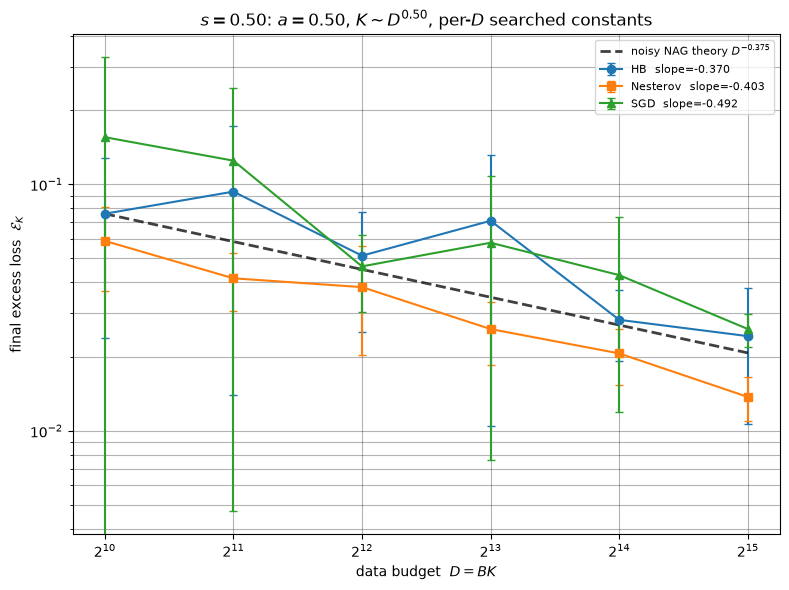

In [76]:
fig, ax = plt.subplots(figsize=(8.0, 6.0))

markers = {'HB': 'o', 'Nesterov': 's', 'SGD': '^'}
base_scaling = EXPERIMENT_RESULTS['base_scaling']
results = EXPERIMENT_RESULTS['results']
p_theory = base_scaling['p_star']
slopes = {}

for name in ALGOS:
    mean = np.array(results[name]['mean'])
    std = np.array(results[name]['std'])
    slope, intercept = np.polyfit(np.log(D_ARRAY), np.log(mean), 1)
    slopes[name] = slope
    label = f"{name}  slope={slope:.3f}"
    ax.errorbar(D_LIST, mean, yerr=std, marker=markers[name], capsize=3,
                linestyle='-', label=label)

anchor = np.array(results['HB']['mean'])[0]
ref = anchor * (D_ARRAY / D_ARRAY[0]) ** (-p_theory)
theory_label = rf'noisy NAG theory $D^{{-{p_theory:.3f}}}$'
ax.plot(D_LIST, ref, linestyle='--', color=(0, 0, 0, 0.75), linewidth=2, label=theory_label)

ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xlabel('data budget  $D = BK$')
ax.set_ylabel(r'final excess loss  $\mathcal{E}_K$')
ax.set_title(rf"$s={S_VALUE:.2f}$: $a={base_scaling['a']:.2f}$, $K\sim D^{{{base_scaling['k_exp']:.2f}}}$, per-$D$ searched constants")
ax.grid(True, which='both', color=(0, 0, 0, 0.3))
ax.legend(fontsize=8)

print(f"s={S_VALUE:.3f}: theory slope = {-p_theory:.4f}")
for name, sl in slopes.items():
    print(f'  measured slope {name:9s}: {sl:.4f}')

plt.tight_layout()
plt.show()


## 7. Training curves for representative $D$

These curves are diagnostic only. The scaling-law comparison above uses final excess loss at fixed
sample budget $D$.


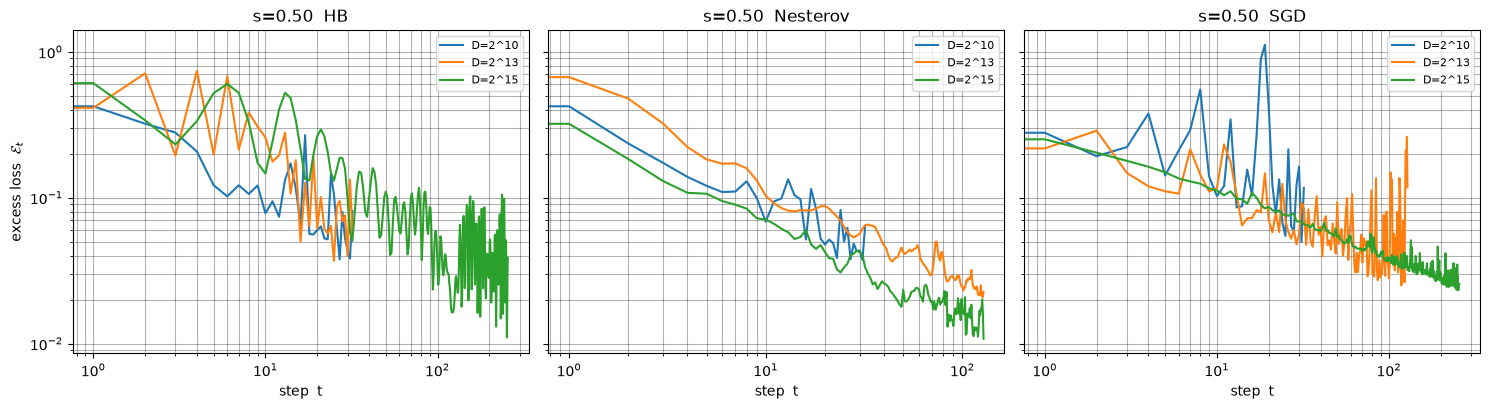

In [77]:
rep_D = [2 ** e for e in (D_EXPONENTS[0], D_EXPONENTS[len(D_EXPONENTS)//2], D_EXPONENTS[-1])]
fig, axes = plt.subplots(1, len(ALGOS), figsize=(15, 4.2), sharey=True)

lam, theta_star = build_problem(s=S_VALUE)
for col, (name, algo) in enumerate(ALGOS.items()):
    ax = axes[col]
    for D in rep_D:
        best = EXPERIMENT_RESULTS['search'][D][name]['best']
        scaling = with_constants(BASE_SCALING, C_B=best['C_B'], C_ETA=best['C_ETA'], C_RHO=best['C_RHO'])
        B, K, eta, rho = common_schedule(D, scaling)
        rng = np.random.default_rng(D)
        _, curve = run_optimizer(algo, B, K, eta, rho, lam, theta_star, rng=rng)
        ax.plot(np.arange(len(curve)), curve, label=f'D=2^{int(np.log2(D))}')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f"s={S_VALUE:.2f}  {name}")
    ax.set_xlabel('step  t')
    ax.grid(True, which='both', color=(0, 0, 0, 0.3))
    ax.legend(fontsize=8)
axes[0].set_ylabel(r'excess loss  $\mathcal{E}_t$')

plt.tight_layout()
plt.show()


## 8. Expected outcome

This notebook supports both noisy-Nesterov branches from the screenshots using a
single `S_VALUE`, enforces $BK=D$, and searches constants separately for every
algorithm and every value of $D$.

- `BETA=2` gives $q=2-1/\beta=1.5$ and threshold $q/2=0.75$.
- If `S_VALUE < 0.75`, the code uses the first branch:
  $a=2s/(s+q)$ and $p^*=sq/(s+q)$.
- If `S_VALUE >= 0.75`, the code uses the second branch:
  $x^*=[s-\frac12(1-1/\beta)]/[s+\frac12(1+1/\beta)]$ and $a$ slightly below
  $(1+x^*)/2$.
- For every plotted $D$, the schedule chooses a power-of-two $B\approx C_BD^a$ and
  sets $K=D/B$, so $B K = D$ exactly on the current power-of-two grid.
- For each pair `(D, algorithm)`, the grid search selects `C_B`, `C_ETA`, and
  `C_RHO` for HB/Nesterov. For SGD, `C_RHO` is fixed because SGD sets $\rho=0$
  internally.
- The default search grids are intentionally small:
  `C_B_GRID=[0.5, 1.0, 2.0]`, `C_ETA_GRID=[0.025, 0.05, 0.10]`, and
  `C_RHO_GRID=[0.5, 1.0, 2.0]`.

For the current default `S_VALUE=0.50`, the first branch gives $a=0.50$, so
$B\approx C_BD^{0.50}$ and $K=D/B$. To run the second branch, set for example
`S_VALUE=1.00` and rerun the notebook.
